### **ShortTerm Memory Implementation using InMemorySaver - Deletion -Summarization**

In [13]:
from langgraph.graph import StateGraph, START, MessagesState
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, RemoveMessage

In [14]:
load_dotenv()

True

In [15]:
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [16]:
class ChatState(MessagesState):
    summary: str

In [17]:
def summarize_conversation(state: ChatState):

    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [
        HumanMessage(content=prompt)
    ]

    response = model.invoke(messages_for_summary)

    # Keep only last 2 messages verbatim
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete],
    }

In [18]:
def chat_node(state: ChatState):
    messages = []

    if state["summary"]:
        messages.append({
            "role": "system",
            "content": f"Conversation summary:\n{state['summary']}"
        })

    messages.extend(state["messages"])

    print(messages)

    response = model.invoke(messages)
    return {"messages": [response]}

In [19]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [20]:
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)
builder.add_node("summarize", summarize_conversation)

builder.add_edge(START, "chat")

builder.add_conditional_edges(
    "chat",
    should_summarize,
    {
        True: "summarize",
        False: "__end__",
    }
)

builder.add_edge("summarize", "__end__")

In [21]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

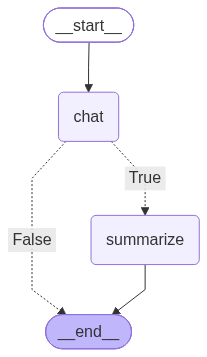

In [22]:
graph

In [23]:
config = {"configurable": {"thread_id": "t1"}}

def run_turn(text: str):
    out = graph.invoke({"messages": [HumanMessage(content=text)], "summary": ""}, config=config)
    return out

In [24]:

# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [25]:
run_turn('Quantum Computing')
show_state()

[HumanMessage(content='Quantum Computing', additional_kwargs={}, response_metadata={}, id='e7880999-3896-4e70-96c4-81151cdee362')]

--- STATE ---
summary: 
num_messages: 2
messages:
- HumanMessage : Quantum Computing
- AIMessage : Quantum computing represents a radical departure from classical computing, lever


In [26]:
run_turn('How is Albert Einstien related?')
show_state()

[HumanMessage(content='Quantum Computing', additional_kwargs={}, response_metadata={}, id='e7880999-3896-4e70-96c4-81151cdee362'), AIMessage(content='Quantum computing represents a radical departure from classical computing, leveraging the principles of quantum mechanics to solve problems that are intractable for even the most powerful supercomputers today. It\'s not just a faster classical computer; it\'s an entirely different way of processing information.\n\nHere\'s a breakdown of what quantum computing is, how it works, its potential, and its challenges:\n\n## The Core Difference: Qubits vs. Bits\n\n**Classical Computers:**\n*   Store information in **bits**, which can represent either a **0 or a 1** at any given time.\n*   Process information sequentially using logic gates.\n*   Are excellent for tasks like word processing, internet browsing, and scientific simulations that rely on classical physics.\n\n**Quantum Computers:**\n*   Store information in **qubits**, which can represe

ChatGoogleGenerativeAIError: Error calling model 'gemini-2.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 2h40m23.193546104s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'descript